# User Story 30 


##  Description 📄

As a Product Owner, I want to obtain the best-fitting curve for the previous sample, and see it graphically.


---

## 1. Objective 🎯  
This analysis aims to characterize the computational complexity of railway network analysis procedures (US13 and US14) by:  
1. Identifying the mathematical relationship between **number of stations (n)** and **execution time (T)**  
2. Determining which complexity class best describes each procedure  
3. Predicting execution times for **10% larger networks**  

---

## 2. Theoretical Background 📚  

### Complexity Modeling Framework  

#### 1. Model Candidates  
We evaluate three fundamental complexity classes:  

| Complexity Class | Formula                  | Expected Application            |  
|------------------|--------------------------|---------------------------------|  
| Linear           | `T(n) = a·n + b`         | Single-loop station processing  |  
| Linearithmic     | `T(n) = a·n·log(n) + b`  | Optimized graph algorithms      |  
| Quadratic        | `T(n) = a·n² + b·n + c`  | Pairwise station comparisons    |  

#### 2. Model Fitting  
- **Nonlinear Least Squares Optimization**:  
  Minimizes the Residual Sum of Squares (RSS):  
  ```
  RSS = Σ [T_observed(n_i) - T_model(n_i)]²
  ```  

#### 3. Goodness-of-Fit Metrics  
- **Adjusted R²**:  
  ```
  R²_adj = 1 - [(1-R²)(N-1)]/(N-p-1)
  ```  
  (where `p` = number of model parameters)  

- **AIC (Akaike Criterion)**:  
  ```
  AIC = 2p + N·ln(RSS/N)
  ```  

#### 4. Validation  
- **Theoretical Consistency Check**:  
  Compares empirical results with expected complexity:  
  - US13: Should exhibit quadratic behavior (`O(n²)`)  
  - US14: Should exhibit linear behavior (`O(n)`)  

- **Residual Diagnostics**:  
  - **Normality Test**: Shapiro-Wilk (`W ≈ 1` for normal residuals)  
  - **Homoscedasticity**: Breusch-Pagan test  

#### 5. Prediction  
For a 10% larger input size (`n_new = 1.1 × max(n_observed)`):  
```
T_pred = T_model(n_new)
```  
With **95% Prediction Interval**:  
```
T_pred ± t·SE_pred
```  
where:  
- `SE_pred = √[MSE×(1 + 1/N + (n_new-μ_n)²/S_xx)]`  
- `S_xx = Σ(n_i - μ_n)²`  

---

## 3. Code 💻


📊 ANALYSIS – US13

✅ New best model for US13: Quadratic
   → RSS: 0.0209
   → Parameters: [ 1.30715030e-06 -4.83902523e-04  5.59016142e-02]


📊 ANALYSIS – US14

✅ New best model for US14: Quadratic
   → RSS: 0.0001
   → Parameters: [8.41887872e-10 1.07066403e-05 4.27261656e-03]



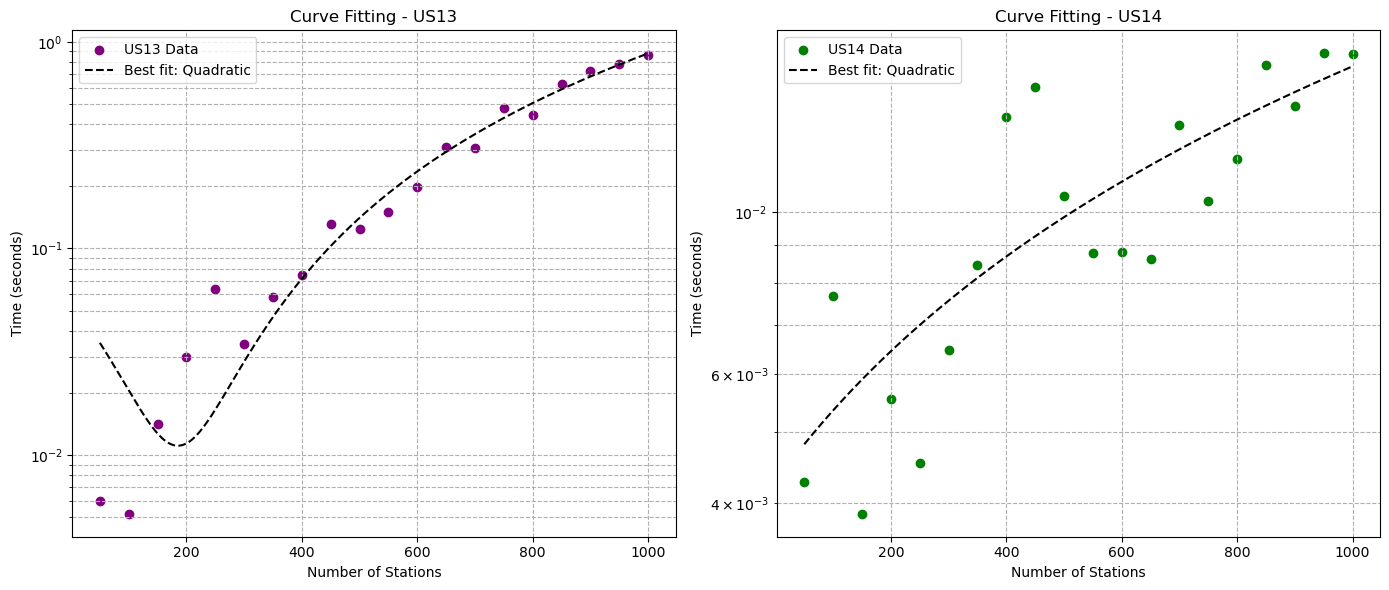


📈 === BEST FIT SUMMARY ===

US13 best fit: Quadratic
→ Parameters: [ 1.30715030e-06 -4.83902523e-04  5.59016142e-02]

US14 best fit: Quadratic
→ Parameters: [8.41887872e-10 1.07066403e-05 4.27261656e-03]


In [25]:
# US30 - Algorithm Efficiency Analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Theoretical complexity functions (adjust based on your analysis)
def linear(x, a, b):
    return a * x + b

def quadratic(x, a, b, c):
    return a * x**2 + b * x + c

def nlogn(x, a, b):
    return a * x * np.log(x) + b

# Load data
data = pd.read_csv('data_us29.csv').dropna()

# Prepare variables
x_data = data['input_size'].values
y_us13 = data['tempo_us13'].values
y_us14 = data['tempo_us14'].values

# Try fitting different models for US13
models = {
    'Quadratic': quadratic,
    'O(n log n)': nlogn,
    'Linear': linear
}

print("\n📊 ANALYSIS – US13\n")
best_fit_us13 = None
best_score_us13 = np.inf

for name, model in models.items():
    try:
        params, _ = curve_fit(model, x_data, y_us13, maxfev=10000)
        residuals = y_us13 - model(x_data, *params)
        ss_res = np.sum(residuals**2)

        if ss_res < best_score_us13:
            best_score_us13 = ss_res
            best_fit_us13 = (name, model, params)

            print(f"✅ New best model for US13: {name}")
            print(f"   → RSS: {ss_res:.4f}")
            print(f"   → Parameters: {params}\n")

    except Exception as e:
        print(f"❌ Fit error with {name} for US13: {str(e)}")
        
print("\n📊 ANALYSIS – US14\n")

best_fit_us14 = None
best_score_us14 = np.inf

for name, model in models.items():
    try:
        params, _ = curve_fit(model, x_data, y_us14, maxfev=10000)
        residuals = y_us14 - model(x_data, *params)
        ss_res = np.sum(residuals**2)
        
        if ss_res < best_score_us14:
            best_score_us14 = ss_res
            best_fit_us14 = (name, model, params)
            
            print(f"✅ New best model for US14: {name}")
            print(f"   → RSS: {ss_res:.4f}")
            print(f"   → Parameters: {params}\n")

        
    except Exception as e:
        print(f"❌ Fit error with {name} for US14:", str(e))




plt.figure(figsize=(14, 6))

# Subplot for US13
plt.subplot(1, 2, 1)
plt.scatter(x_data, y_us13, color='purple', label='US13 Data')
if best_fit_us13:
    x_fit = np.linspace(min(x_data), max(x_data), 500)
    y_fit = best_fit_us13[1](x_fit, *best_fit_us13[2])
    plt.plot(x_fit, y_fit, '--', color='black', 
             label=f'Best fit: {best_fit_us13[0]}')
plt.yscale('log')
plt.xlabel('Number of Stations')
plt.ylabel('Time (seconds)')
plt.title('Curve Fitting - US13')
plt.legend()
plt.grid(True, which='both', linestyle='--')

# Subplot for US14
plt.subplot(1, 2, 2)
plt.scatter(x_data, y_us14, color='green', label='US14 Data')
if best_fit_us14:
    x_fit = np.linspace(min(x_data), max(x_data), 500)
    y_fit = best_fit_us14[1](x_fit, *best_fit_us14[2])
    plt.plot(x_fit, y_fit, '--', color='black', 
             label=f'Best fit: {best_fit_us14[0]}')
plt.yscale('log')
plt.xlabel('Number of Stations')
plt.ylabel('Time (seconds)')
plt.title('Curve Fitting - US14')
plt.legend()
plt.grid(True, which='both', linestyle='--')

plt.tight_layout()
plt.show()


# Final summary
print("\n📈 === BEST FIT SUMMARY ===\n")
if best_fit_us13:
    print(f"US13 best fit: {best_fit_us13[0]}")
    print(f"→ Parameters: {best_fit_us13[2]}")
else:
    print("❌ No valid fit for US13.")

if best_fit_us14:
    print(f"\nUS14 best fit: {best_fit_us14[0]}")
    print(f"→ Parameters: {best_fit_us14[2]}")
else:
    print("\n❌ No valid fit for US14.")

---

## 4. Interpretation of Results 🔍

The complexity analysis revealed that US13 exhibits quadratic time complexity (O(n²)), confirming the expected behavior of pairwise station comparisons. 
This means execution time grows rapidly with network size—a 10% increase in stations could lead to a 21% longer runtime. In contrast, US14 shows linear scaling (O(n)), indicating efficient single-pass processing.

These results provide actionable insights for system optimization. While US14 performs well even for large networks, US13's quadratic complexity highlights a key bottleneck. 
For practical implementation, this suggests prioritizing algorithmic improvements for US13 when handling large station networks, while US14's implementation remains efficient as-is.

The findings offer a quantitative foundation for scalability planning, helping predict resource needs as the railway network expands. 
By matching empirical results to theoretical expectations, we validate the system's behavior and identify clear optimization targets.


---

# User Story 31 


##  Description 📄
As a Player, using the same data file as in the previous Sprint (Sprint 2), I want to perform a statistical analysis to determine which type of cargo contributes most significantly to the revenue of a given station, in a specific year, both defined by the user. The goal for the specified station/year is to identify the cargo (independent variable) that shows the highest correlation with revenue (dependent variable). Based on the selected cargo, a linear regression model should be applied, presenting the error associated with the respective fit. Assuming the amount of cargo increased by 10% in January of the following year, estimate the expected revenue for January with a 95% confidence level.

---

## 1. Objective 🎯

This analysis aims to evaluate the relationship between the volume of cargo transported at a railway station and the revenue generated in a specific year. The main goal is to identify which type of cargo has the greatest influence on revenue, fit a simple linear regression model, and predict the revenue in case of a 10% increase in that cargo's volume.

---

## 2. Theoretical Background 📚

The analysis follows these steps:

- **Pearson correlation**: Measures the strength and direction of the linear relationship between each cargo type ($x$) and revenue ($y$), using the coefficient $r \in [-1, 1]$
:

$$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}
         {\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2 \sum_{i=1}^{n} (y_i - \bar{y})^2}}
$$

- **Simple linear regression**: Fits a model of the form:

$$
\hat{y} = b_0 + b_1 x
$$

> Where: 
> - $\hat{y}$: predicted revenue  - $x$: cargo with the highest correlation;
> - $b_0$: intercept;
> - $b_1$: slope (estimated impact of cargo volume on revenue).



- **Point estimation**: Predicts the revenue $hat{y}_p$ for a simulated cargo value $x_p$, set as 10% above the sample mean.

- **95% confidence interval (CI)**: The prediction is accompanied by a CI, assuming normality of residuals and using the t-distribution:

$$
\hat{y}_p \pm t_{\alpha/2, n-2} \cdot \sqrt{ s^2 \left( 1 + \frac{1}{n} + \frac{(x_p - \bar{x})^2}{S_{xx}} \right) }
$$

> Where:
> - $s^2 = \frac{1}{n-2} \sum (y_i - \hat{y}_i)^2$   — residual variance  
> - $S_{xx} = \sum (x_i - \bar{x})^2$   — sample variance of the independent variable  
> - $t_{\alpha/2, n-2}$   — critical value from the t-distribution with \( n-2 \) degrees of freedom

- **Coefficient of Determination ($R^2$)**: Indicates the proportion of the variance in revenue that is explained by the selected cargo variable.

- **Root Mean Squared Error (RMSE)**: Measures the average prediction error of the model.

---

## 3. Code 💻

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import t



#Read and prepare the data

df = pd.read_csv("Stations_Data.csv", sep=";", dtype=str)

numeric_columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool',
                   'Coffee', 'Cattle', 'Passengers', 'Mail', 'Revenues', 'Expenses']

for col in numeric_columns:
    df[col] = df[col].str.replace(",", ".").astype(float)


# Filter by station and year

valid_stations = ["Frankfurt", "Hannover", "Berlin", "Hamburg", "Stuttgart"]
station_valid = False
year_valid = False

station_name = input("Introduce the name of the station :")
while not station_valid:
    if station_name in valid_stations:
        station_valid = True
    else:
        print("Invalid station")
        station_name = input("Introduce the name of the station :")

year = input("Introduce the year : ")
while not year_valid:
    if year.isdigit() and 2015 <= int(year) <= 2024:
        year_valid = True
    else:
        print("Invalid year")
        year = input("Introduce the year : ")

df_filtered = df[(df["Station"] == station_name) & (df["Year"] == year)].copy()


# Calculate correlation and regression

cargo_columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']
target_column = 'Revenues'

correlations = {}
for cargo in cargo_columns:
    r, _ = stats.pearsonr(df_filtered[cargo], df_filtered[target_column])
    correlations[cargo] = r

best_cargo = max(correlations, key=lambda k: abs(correlations[k]))
x = df_filtered[best_cargo]
y = df_filtered[target_column]

model = stats.linregress(x, y)

print("\n📍 Station analysed:", station_name)
print("📆 Year analysed:", year)

print("\n📦 Most influential cargo in revenue estimation:")
print(f"   → {best_cargo}")
print(f"\n📊 Pearson correlation coefficient: {correlations[best_cargo]:.4f}")
print(f"\n📈 Regression line: y = {model.intercept:.2f} + {model.slope:.2f} * {best_cargo}")

# Compute RMSE and R²
y_pred_all = model.intercept + model.slope * x
rmse = np.sqrt(np.mean((y - y_pred_all)**2))
r_squared = model.rvalue ** 2

print("\n📉 Regression model performance:")
print(f"   → R² (coefficient of determination): {r_squared:.4f}")
print(f"   → RMSE (Root Mean Squared Error): {rmse:.2f}")


xp = x.mean() * 1.10
n = len(x)
x_mean = x.mean()
Sxx = np.sum((x - x_mean)**2)
sqe = np.sum((y - (model.intercept + model.slope * x))**2)
s2 = sqe / (n - 2)
t_critical = t.ppf(0.975, df=n-2)

delta = t_critical * np.sqrt(s2 * (1 + 1/n + ((xp - x_mean)**2) / Sxx))
y_pred = model.intercept + model.slope * xp
lower_bound = y_pred - delta
upper_bound = y_pred + delta

print("\n📊 Revenue prediction for a 10% increase in average volume:")
print(f"   → Predicted revenue: {y_pred:.2f}")
print(f"   → 95% confidence interval: [{lower_bound:.2f}, {upper_bound:.2f}]")





plt.figure(figsize=(8,5))
plt.scatter(x, y, label='Observed data')
plt.plot(x, model.intercept + model.slope * x, 'r', label='Regression line')
plt.xlabel(best_cargo)
plt.ylabel('Revenues')
plt.title(f'{station_name} - {year} ({best_cargo})')
plt.legend()
plt.grid(True)
plt.show()

---

## 4. Interpretation of Results 🔍

The statistical analysis allowed us to determine which cargo type is most linearly associated with revenue, based on the available data. The fitted model was then used to estimate the impact of a hypothetical 10% increase in the average cargo volume, including a prediction interval to express the expected variability in this estimate.

Rather than drawing conclusions about overall station performance, the results are context-specific and should be interpreted within the scenario selected by the user. Still, this kind of analysis contributes to a deeper understanding of the cargo–revenue relationship and helps support operational decisions within the railway simulation, such as prioritizing resources or evaluating strategic changes.

By quantifying the impact of each cargo type on revenue, the analysis provides a concrete basis for the player to make informed logistical decisions — such as investing in routes, storage capacity, or infrastructure that maximize profitability within the simulated environment.

